# TCN — Eğitim Verisindeki RUL Dağılımının İncelenmesi

## Amaç ve veri kapsamı

Bu çalışmada, yüksek RUL değerlerindeki tahmin hatalarının eğitim
pencerelerinde bu değerlerin daha az temsil edilmesiyle ilişkili
olup olmadığı araştırılacaktır.

N-CMAPSS DS02-006 development verisinden oluşturulan, pencere uzunluğu
256 ve stride değeri 256 olan metadata kullanılacaktır.
Resmî test motorları analize dahil edilmeyecektir.

Analiz birimi ham sensör satırı değil, modelin kullandığı penceredir.
Uçuş düzeyindeki sayımlarda motor ve uçuş numarası birlikte
benzersiz uçuş kimliği olarak kullanılacaktır.

Önce development pencerelerinin genel dağılımı, ardından altı LOEO
fold’unun eğitim ve validation dağılımları incelenecektir.
Genel development kümesi tek bir fold’un eğitim kümesi değildir.

Dağılım dengesizliği hipotezi destekleyebilir; ancak tek başına
tahmin hatalarının nedenini kanıtlamaz. Bu aşamada model eğitimi
veya veri dağılımını değiştiren bir işlem yapılmayacaktır.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Proje kökünden veya n_cmapss/tcn_notebooks içinden çalışabilir.
PROJECT_ROOT = next(
    (
        path for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "n_cmapss/preprocessing/data_loader.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Proje kökü bulunamadı; kernel konumunu kontrol et.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from n_cmapss.preprocessing.config import WINDOW_SIZE, STRIDE
from n_cmapss.preprocessing.data_loader import (
    WINDOW_METADATA_PATH,
    SPLIT_FOLDS_PATH,
    load_window_metadata,
    split_windows_by_fold,
)

expected_dir = (
    PROJECT_ROOT / "n_cmapss/processed/window_256_stride_256"
)

assert WINDOW_SIZE == 256 and STRIDE == 256
assert WINDOW_METADATA_PATH.resolve() == (
    expected_dir / "window_metadata.csv"
).resolve(), "Loader farklı bir veri sürümüne yönleniyor."
assert SPLIT_FOLDS_PATH.resolve() == (
    expected_dir / "split_folds.json"
).resolve()
assert WINDOW_METADATA_PATH.is_file()
assert SPLIT_FOLDS_PATH.is_file()

# Eğitim pipeline'ıyla aynı metadata yükleyicisini kullan.
windows = load_window_metadata()
metadata = pd.DataFrame(asdict(window) for window in windows)

assert not metadata.empty
assert metadata["window_id"].is_unique
assert np.isfinite(metadata.to_numpy(dtype=float)).all()
assert metadata["start_row"].ge(0).all()
assert (metadata["end_row"] - metadata["start_row"]).eq(256).all()
assert not metadata.duplicated(["start_row", "end_row"]).any()

DEV_UNITS = {2, 5, 10, 16, 18, 20}
TEST_UNITS = {11, 14, 15}

assert set(metadata["unit"]) == DEV_UNITS
assert set(metadata["unit"]).isdisjoint(TEST_UNITS)
assert metadata["rul"].ge(0).all()
assert metadata["rul"].mod(1).eq(0).all()

# Aynı uçuşun bütün pencerelerinde RUL sabit olmalı.
assert (
    metadata.groupby(["unit", "cycle"])["rul"]
    .nunique()
    .eq(1)
    .all()
)

# Uçuş içindeki pencere başlangıçları stride=256 ile ilerlemeli.
ordered = metadata.sort_values(["unit", "cycle", "start_row"])
start_differences = (
    ordered.groupby(["unit", "cycle"])["start_row"].diff().dropna()
)
assert start_differences.eq(256).all()

# Uçuş düzeyindeki dağılım için her motor–uçuşu bir kez tut.
flights = (
    metadata[["unit", "cycle", "rul"]]
    .drop_duplicates(["unit", "cycle"])
    .reset_index(drop=True)
)

print("Metadata:", WINDOW_METADATA_PATH)
print(f"Pencere uzunluğu: {WINDOW_SIZE} | Stride: {STRIDE}")
print("Pencere sayısı:", len(metadata))
print("Benzersiz motor–uçuş sayısı:", len(flights))
print("Development motorları:", sorted(metadata["unit"].unique()))
print("RUL aralığı:", metadata["rul"].min(), "–", metadata["rul"].max())
print("Metadata kontrolleri başarılı; resmî test motorları bulunmuyor.")

display(metadata.head())

Metadata: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance/n_cmapss/processed/window_256_stride_256/window_metadata.csv
Pencere uzunluğu: 256 | Stride: 256
Pencere sayısı: 20339
Benzersiz motor–uçuş sayısı: 446
Development motorları: [np.int64(2), np.int64(5), np.int64(10), np.int64(16), np.int64(18), np.int64(20)]
RUL aralığı: 0.0 – 88.0
Metadata kontrolleri başarılı; resmî test motorları bulunmuyor.


,window_id,unit,cycle,rul,start_row,end_row
0,0,2,1,74.0,0,256
1,1,2,1,74.0,256,512
2,2,2,1,74.0,512,768
3,3,2,1,74.0,768,1024
4,4,2,1,74.0,1024,1280


## Genel RUL Dağılımı

Development pencereleri beş RUL aralığında incelenecektir:
0–20, 21–40, 41–60, 61–80 ve 81 ve üzeri.

Her aralık için pencere sayısı ve yüzdesi ile benzersiz motor–uçuş
sayısı ve uçuş yüzdesi hesaplanacaktır.

Pencere yüzdesi, ilgili aralığın model girdileri içindeki payını;
uçuş yüzdesi ise her uçuş bir kez sayıldığında elde edilen payı gösterir.
Uzun uçuşlar daha fazla pencere üretebildiğinden bu oranlar farklılaşabilir.

Histogramda her tam sayı RUL değeri ayrı bir kutuda gösterilecektir.
Böylece aralıkların farklı genişliklerinin sayımlara etkisi görülebilir.
Özellikle 81 ve üzeri aralığı mevcut veride yalnızca 81–88 değerlerini kapsar.

Bu genel dağılım bütün development motorlarını içerir.
Her LOEO fold’unun gerçek eğitim dağılımı ayrıca incelenecektir.

,Pencere sayısı,Pencere yüzdesi (%),Benzersiz motor–uçuş sayısı,Uçuş yüzdesi (%)
Gerçek RUL aralığı,,,,
0–20,5625,27.66,126,28.25
21–40,5541,27.24,120,26.91
41–60,5439,26.74,120,26.91
61–80,3378,16.61,71,15.92
81 ve üzeri,356,1.75,9,2.02


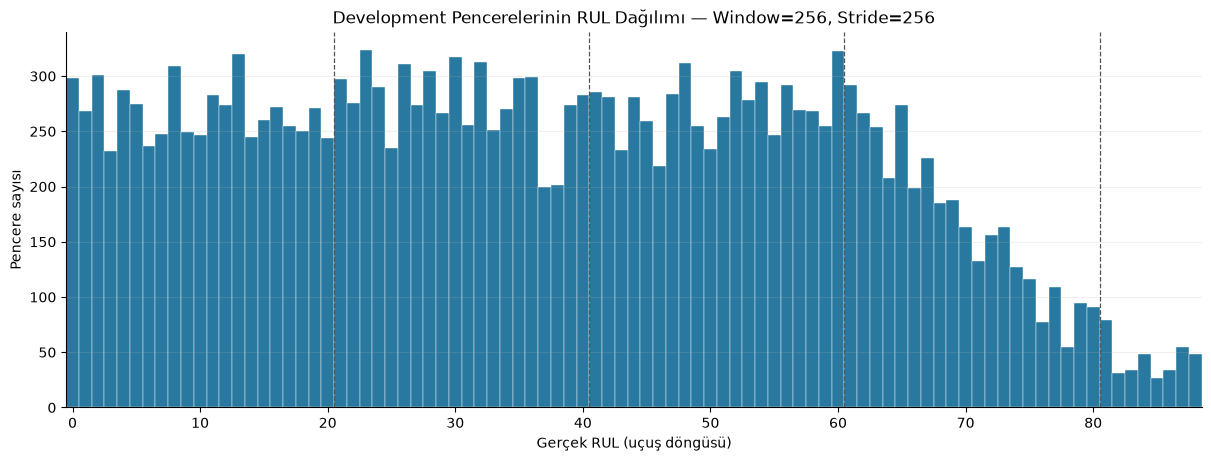

In [2]:
RUL_LABELS = ["0–20", "21–40", "41–60", "61–80", "81 ve üzeri"]
RUL_BINS = [0, 20, 40, 60, 80, np.inf]

for frame in (metadata, flights):
    frame["rul_group"] = pd.cut(
        frame["rul"],
        bins=RUL_BINS,
        labels=RUL_LABELS,
        include_lowest=True,
        right=True,
        ordered=True,
    )
    assert frame["rul_group"].notna().all()

window_counts = (
    metadata.groupby("rul_group", observed=False).size()
)
flight_counts = (
    flights.groupby("rul_group", observed=False).size()
)

rul_distribution = pd.DataFrame({
    "Pencere sayısı": window_counts,
    "Pencere yüzdesi (%)": 100 * window_counts / len(metadata),
    "Benzersiz motor–uçuş sayısı": flight_counts,
    "Uçuş yüzdesi (%)": 100 * flight_counts / len(flights),
}).rename_axis("Gerçek RUL aralığı")

assert window_counts.sum() == len(metadata)
assert flight_counts.sum() == len(flights)
assert np.isclose(rul_distribution["Pencere yüzdesi (%)"].sum(), 100)
assert np.isclose(rul_distribution["Uçuş yüzdesi (%)"].sum(), 100)

display(
    rul_distribution.style.format({
        "Pencere sayısı": "{:d}",
        "Pencere yüzdesi (%)": "{:.2f}",
        "Benzersiz motor–uçuş sayısı": "{:d}",
        "Uçuş yüzdesi (%)": "{:.2f}",
    })
)

# Her tam sayı RUL için bir histogram kutusu.
max_rul = int(metadata["rul"].max())
histogram_bins = np.arange(-0.5, max_rul + 1.5, 1)

fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)

ax.hist(
    metadata["rul"],
    bins=histogram_bins,
    color="#2878A0",
    edgecolor="white",
    linewidth=0.3,
)

for boundary in [20.5, 40.5, 60.5, 80.5]:
    ax.axvline(
        boundary, color="#555555",
        linestyle="--", linewidth=0.9,
    )

ax.set(
    title="Development Pencerelerinin RUL Dağılımı — Window=256, Stride=256",
    xlabel="Gerçek RUL (uçuş döngüsü)",
    ylabel="Pencere sayısı",
    xlim=(-0.5, max_rul + 0.5),
)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.show()

## LOEO Fold’larında Eğitim ve Validation Dağılımları

Genel development dağılımında yüksek RUL değerlerinin temsili
azalmaktadır. Pencere ve uçuş yüzdelerinin birbirine yakın olması,
bu azalmanın yalnızca uçuşların farklı sayıda pencere üretmesinden
kaynaklanmadığını göstermektedir.

Ancak her LOEO modeli yalnızca beş motorla eğitilir.
Bu nedenle genel dağılım, tek bir modelin eğitimde gördüğü
RUL dağılımını doğrudan temsil etmez.

Aşağıda pipeline’ın mevcut fold ayırma fonksiyonu kullanılarak
her fold için eğitim ve validation pencere sayıları ve yüzdeleri
RUL aralıklarına göre karşılaştırılacaktır.

Yüzdeler, ilgili fold’un eğitim veya validation toplamına göre
ayrı ayrı hesaplanacaktır. Böylece farklı küme büyüklüklerinin
karşılaştırmayı yanıltması önlenecektir.

In [3]:
fold_data = {}
distribution_rows = []
validation_ids_seen = []

for fold_number in range(1, 7):
    train_windows, validation_windows = split_windows_by_fold(
        windows,
        fold_number=fold_number,
    )

    train = pd.DataFrame(asdict(window) for window in train_windows)
    validation = pd.DataFrame(
        asdict(window) for window in validation_windows
    )

    assert not train.empty and not validation.empty

    train_units = set(train["unit"])
    validation_units = set(validation["unit"])

    assert len(train_units) == 5 and len(validation_units) == 1
    assert train_units.isdisjoint(validation_units)
    assert train_units | validation_units == DEV_UNITS

    train_ids = set(train["window_id"])
    validation_ids = set(validation["window_id"])

    assert train["window_id"].is_unique
    assert validation["window_id"].is_unique
    assert train_ids.isdisjoint(validation_ids)
    assert train_ids | validation_ids == set(metadata["window_id"])

    validation_ids_seen.extend(validation["window_id"].tolist())

    for frame in (train, validation):
        frame["rul_group"] = pd.cut(
            frame["rul"],
            bins=RUL_BINS,
            labels=RUL_LABELS,
            include_lowest=True,
            right=True,
            ordered=True,
        )
        assert frame["rul_group"].notna().all()

    # Sonraki maksimum RUL/kapsam analizinde yeniden kullanacağız.
    fold_data[fold_number] = {
        "train": train,
        "validation": validation,
    }

    train_counts = train.groupby("rul_group", observed=False).size()
    validation_counts = (
        validation.groupby("rul_group", observed=False).size()
    )

    assert train_counts.sum() == len(train)
    assert validation_counts.sum() == len(validation)

    validation_unit = int(next(iter(validation_units)))

    for label in RUL_LABELS:
        distribution_rows.append({
            "Fold": fold_number,
            "Validation motoru": validation_unit,
            "RUL aralığı": label,
            "Eğitim penceresi": int(train_counts.loc[label]),
            "Eğitim (%)": 100 * train_counts.loc[label] / len(train),
            "Validation penceresi": int(validation_counts.loc[label]),
            "Validation (%)": (
                100 * validation_counts.loc[label] / len(validation)
            ),
        })

# Her development penceresi tam bir kez validation olmalı.
assert len(validation_ids_seen) == len(metadata)
assert len(set(validation_ids_seen)) == len(metadata)

fold_distribution = (
    pd.DataFrame(distribution_rows)
    .set_index(["Fold", "Validation motoru", "RUL aralığı"])
)

display(
    fold_distribution.style.format({
        "Eğitim penceresi": "{:d}",
        "Eğitim (%)": "{:.2f}",
        "Validation penceresi": "{:d}",
        "Validation (%)": "{:.2f}",
    })
)

print("Altı LOEO fold doğrulandı; her pencere bir kez validation oldu.")

Altı LOEO fold doğrulandı; her pencere bir kez validation oldu.


## Eğitim RUL Kapsamını Aşan Validation Değerleri

Fold bazındaki dağılımlar, özellikle Motor 5’in validation olduğu
Fold 2’de yüksek RUL temsilinin eğitim ve validation arasında
farklılaştığını göstermektedir.

Her fold için eğitim ve validation maksimum RUL değerleri
karşılaştırılacaktır. Eğitim maksimumunu kesin olarak aşan
validation pencereleri ve benzersiz motor–uçuşlar sayılacaktır.

Bu kayıtlar, hedef değer bakımından eğitimde gözlenen üst sınırın
dışındadır. Ancak eğitim maksimumunun altında kalmak da yeterli
örnek yoğunluğu veya benzer operasyonel koşullar bulunduğunu
garanti etmez.

Yüzdeler ilgili fold’un bütün validation pencereleri ve uçuşları
üzerinden ayrı ayrı hesaplanacaktır.

In [4]:
coverage_rows = []
beyond_training_range = {}

for fold_number, data in sorted(fold_data.items()):
    train = data["train"]
    validation = data["validation"]

    train_max = float(train["rul"].max())
    validation_max = float(validation["rul"].max())

    validation_flights = (
        validation[["unit", "cycle", "rul"]]
        .drop_duplicates(["unit", "cycle"])
    )

    beyond_windows = validation.loc[
        validation["rul"].gt(train_max)
    ].copy()

    beyond_flights = validation_flights.loc[
        validation_flights["rul"].gt(train_max)
    ]

    assert len(beyond_windows) <= len(validation)
    assert len(beyond_flights) <= len(validation_flights)
    assert (
        len(beyond_windows[["unit", "cycle"]].drop_duplicates())
        == len(beyond_flights)
    )

    beyond_training_range[fold_number] = beyond_windows

    coverage_rows.append({
        "Fold": fold_number,
        "Validation motoru": int(validation["unit"].iloc[0]),
        "Eğitim maksimum RUL": train_max,
        "Validation maksimum RUL": validation_max,
        "Sınırı aşan pencere": len(beyond_windows),
        "Validation pencere payı (%)": (
            100 * len(beyond_windows) / len(validation)
        ),
        "Sınırı aşan uçuş": len(beyond_flights),
        "Validation uçuş payı (%)": (
            100 * len(beyond_flights) / len(validation_flights)
        ),
    })

rul_coverage = pd.DataFrame(coverage_rows)

display(
    rul_coverage.style.hide(axis="index").format({
        "Eğitim maksimum RUL": "{:.0f}",
        "Validation maksimum RUL": "{:.0f}",
        "Sınırı aşan pencere": "{:d}",
        "Validation pencere payı (%)": "{:.2f}",
        "Sınırı aşan uçuş": "{:d}",
        "Validation uçuş payı (%)": "{:.2f}",
    })
)

print(
    "Eğitim maksimumunu aşan validation değeri bulunan fold sayısı:",
    rul_coverage["Sınırı aşan pencere"].gt(0).sum(),
)

Fold,Validation motoru,Eğitim maksimum RUL,Validation maksimum RUL,Sınırı aşan pencere,Validation pencere payı (%),Sınırı aşan uçuş,Validation uçuş payı (%)
1,2,88,74,0,0.00,0,0.00
2,5,81,88,277,6.94,7,7.87
3,10,88,81,0,0.00,0,0.00
4,16,88,62,0,0.00,0,0.00
5,18,88,70,0,0.00,0,0.00
6,20,88,65,0,0.00,0,0.00


Eğitim maksimumunu aşan validation değeri bulunan fold sayısı: 1


## Sonuç ve Değerlendirme

### 1. Yüksek RUL değerlerinin temsili azalıyor

20.339 development penceresinin dağılımında:

- 0–20, 21–40 ve 41–60 aralıklarının her biri yaklaşık %27 paya sahiptir.
- 61–80 aralığının payı %16,61’dir.
- 81 ve üzerindeki 356 pencere, toplamın yalnızca %1,75’ini oluşturur
  ve 9 farklı motor–uçuşa aittir.

81 ve üzeri aralığı yalnızca 81–88 değerlerini kapsadığından diğer
aralıklardan daha dardır. Bununla birlikte, birer RUL değerini gösteren
histogramda da yüksek RUL’a doğru örnek sayısının azaldığı görülmektedir.
Dolayısıyla fark yalnızca aralık genişliklerinden kaynaklanmamaktadır.

Pencere ve uçuş yüzdelerinin yakın olması, azalmanın yalnızca uçuşların
farklı sayıda pencere üretmesiyle açıklanamayacağını göstermektedir.

### 2. En belirgin eğitim–validation kapsam farkı Motor 5’te

Motor 5’in validation olduğu Fold 2’de:

- RUL 61–80 payı eğitimde %14,60, validation’da %24,84’tür.
- RUL ≥81 payı eğitimde %0,25, validation’da %7,89’dur.
- Eğitim maksimum RUL değeri 81, validation maksimumu 88’dir.
- Validation’daki 277 pencere ve 7 uçuş, eğitim maksimumunu aşmaktadır.
- Bu kayıtlar validation pencerelerinin %6,94’ünü, uçuşlarının %7,87’sini
  oluşturmaktadır.

Bu fold’da yüksek RUL hem eğitimde daha az temsil edilmekte hem de
validation’ın bir bölümü eğitimde gözlenen hedef aralığının dışında
kalmaktadır. Modelden RUL 82–88 aralığına genelleme yapması beklenmektedir.

### 3. Diğer fold’larda maksimum kapsam aşımı yok

Diğer beş fold’da validation maksimum RUL değeri eğitim maksimumunu
aşmamaktadır. Bununla birlikte, eğitim aralığının içinde bulunmak,
ilgili değerlerin yeterli sayıda veya yeterince çeşitli motor ve uçuşla
temsil edildiğini garanti etmez.

Örneğin Motor 10’un validation olduğu Fold 3’te, 61–80 aralığının payı
eğitimde %14,88 iken validation’da %24,42’dir.

### Araştırma sorusuna yanıt

“Model yüksek RUL değerlerini eğitimde daha az gördüğü için bu
değerlerde zorlanıyor olabilir mi?” hipotezi, **temsil azalması
bakımından desteklenmektedir**. Özellikle Fold 2’de belirgin bir
eğitim–validation dağılım ve hedef kapsamı farkı bulunmaktadır.

Ancak bu ön analiz, dağılım farkının tahmin hatalarının veya eksik
tahmin eğiliminin nedeni olduğunu kanıtlamaz. Aynı zamanda yüksek
RUL’daki bütün hataları yalnızca bu mekanizmayla açıklamaz.

Motor özellikleri, operasyonel koşullar, sağlık durumunun RUL hakkında
taşıdığı bilgi ve modelin öğrenme davranışı da etkili olabilir.

### Sınırlılıklar ve olası sonraki çalışma

- Analiz, modelin kullandığı pencere metadata’sına dayanmaktadır.
  Aynı uçuşun pencereleri bağımsız gözlemler değildir.
- Genel development dağılımı ile her fold’un eğitim dağılımı ayrı
  değerlendirilmiştir. Resmî test motorları kullanılmamıştır.
- Bu çalışma örnek temsilini incelemiştir; yeniden eğitim veya
  nedensel etki değerlendirmesi yapılmamıştır.
- Gerekirse ilk takip analizi, Fold 2’de eğitim kapsamı içindeki
  RUL ≤81 ve kapsam dışındaki RUL 82–88 hatalarını ayrı incelemek olabilir.
- Daha sonra yapılacak kontrollü bir eğitim deneyinde yalnızca
  eğitim verisinin ağırlıklandırılması değiştirilerek aynı validation
  pencerelerinde karşılaştırma yapılabilir. Böyle bir deney, yeni
  RUL değerleri veya bağımsız motor bilgisi üretmez ve kapsam dışına
  genelleme sorununu tek başına çözmez.

Bu kısa ön analiz, yüksek RUL temsilindeki azalmayı ve özellikle
Fold 2’deki kapsam farkını ortaya koyarak tamamlanmıştır.

## Motor 5 — Eğitim RUL Kapsamı ve Tahmin Hataları

Fold 2 modelinin Motor 5 validation tahminleri, gerçek RUL değerine göre
0–60, 61–74, 75–81 ve 82–88 aralıklarında karşılaştırılacaktır.
75–81 aralığı eğitim üst sınırına yakın değerleri, 82–88 aralığı ise
eğitimde gözlenen maksimum RUL olan 81’in üzerindeki değerleri kapsar.

Window=256, stride=256, learning rate=0.001 ve seed=42 koşullarındaki
mevcut tahminler kullanılacaktır. Pencere kimlikleri, motor, uçuş ve
gerçek RUL değerleri Fold 2 metadata’sıyla doğrulanacaktır.

Her aralık için pencere ve benzersiz uçuş sayıları ile pencere bazında
MAE, RMSE ve Bias hesaplanacaktır. Bias, tahmin edilen RUL ile gerçek
RUL arasındaki farktır; negatif değer düşük tahmin eğilimini gösterir.

Aynı uçuşun pencereleri bağımsız gözlemler değildir. Aralıklar arasındaki
hata farkları betimsel olarak değerlendirilecek; eğitim kapsamının
aşılmasının nedensel etkisi olarak yorumlanmayacaktır.

In [5]:
motor5_prediction_path = (
    PROJECT_ROOT
    / "n_cmapss/outputs/tcn/window_256_stride_256"
    / "seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001"
    / "fold_2_20261122_232355_770432"
    / "predictions.csv"
)

motor5_metadata = fold_data[2]["validation"]
motor5_train_max = float(fold_data[2]["train"]["rul"].max())

assert motor5_prediction_path.is_file(), motor5_prediction_path
assert motor5_train_max == 81
assert set(motor5_metadata["unit"]) == {5}

prediction_columns = [
    "window_id", "unit", "cycle", "actual_rul", "predicted_rul"
]
motor5_predictions = pd.read_csv(
    motor5_prediction_path, usecols=prediction_columns
)

assert motor5_predictions["window_id"].is_unique
assert np.isfinite(
    motor5_predictions[prediction_columns].to_numpy(dtype=float)
).all()
assert len(motor5_predictions) == len(motor5_metadata) == 3990
assert set(motor5_predictions["window_id"]) == set(
    motor5_metadata["window_id"]
)

# Satır sırasına güvenmeden pencere kimliği üzerinden doğrula.
motor5_check = motor5_predictions.merge(
    motor5_metadata[["window_id", "unit", "cycle", "rul"]],
    on="window_id",
    how="inner",
    validate="one_to_one",
    suffixes=("", "_metadata"),
)

assert motor5_check["unit"].eq(motor5_check["unit_metadata"]).all()
assert motor5_check["cycle"].eq(motor5_check["cycle_metadata"]).all()
assert motor5_check["actual_rul"].eq(motor5_check["rul"]).all()
assert motor5_predictions["unit"].eq(5).all()
assert motor5_predictions["cycle"].nunique() == 89
assert motor5_predictions["actual_rul"].max() == 88

motor5_outside = motor5_predictions["actual_rul"].gt(motor5_train_max)
assert motor5_outside.sum() == 277
assert motor5_predictions.loc[motor5_outside, "cycle"].nunique() == 7
assert set(
    motor5_predictions.loc[motor5_outside, "window_id"]
) == set(beyond_training_range[2]["window_id"])

# Tahminlere kırpma veya başka bir dönüşüm uygulanmaz.
motor5_predictions["error"] = (
    motor5_predictions["predicted_rul"]
    - motor5_predictions["actual_rul"]
)
motor5_predictions["absolute_error"] = motor5_predictions["error"].abs()
motor5_predictions["squared_error"] = motor5_predictions["error"].pow(2)

motor5_predictions["rul_band"] = pd.cut(
    motor5_predictions["actual_rul"],
    bins=[0, 60, 74, 81, 88],
    labels=["0–60", "61–74", "75–81", "82–88"],
    include_lowest=True,
    right=True,
    ordered=True,
)
assert motor5_predictions["rul_band"].notna().all()

motor5_band_metrics = (
    motor5_predictions.groupby("rul_band", observed=False)
    .agg(
        window_count=("window_id", "size"),
        flight_count=("cycle", "nunique"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean"),
        Bias=("error", "mean"),
    )
)
motor5_band_metrics["RMSE"] = np.sqrt(motor5_band_metrics.pop("MSE"))
motor5_band_metrics = (
    motor5_band_metrics.rename(columns={
        "window_count": "Pencere sayısı",
        "flight_count": "Benzersiz uçuş sayısı",
    })
    [["Pencere sayısı", "Benzersiz uçuş sayısı", "MAE", "RMSE", "Bias"]]
    .rename_axis("Gerçek RUL aralığı")
)

assert motor5_band_metrics["Pencere sayısı"].sum() == 3990
assert motor5_band_metrics["Benzersiz uçuş sayısı"].sum() == 89

print("Doğrulandı: Motor 5 / Fold 2 — 3990 pencere, 89 uçuş.")
print("Eğitim maksimum RUL: 81 | Validation maksimum RUL: 88")
print("Eğitim kapsamı dışında: 277 pencere, 7 uçuş.")

display(motor5_band_metrics.style.format({
    "Pencere sayısı": "{:d}",
    "Benzersiz uçuş sayısı": "{:d}",
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "Bias": "{:+.4f}",
}))

Doğrulandı: Motor 5 / Fold 2 — 3990 pencere, 89 uçuş.
Eğitim maksimum RUL: 81 | Validation maksimum RUL: 88
Eğitim kapsamı dışında: 277 pencere, 7 uçuş.


,Pencere sayısı,Benzersiz uçuş sayısı,MAE,RMSE,Bias
Gerçek RUL aralığı,,,,,
0–60,2684,61,2.7377,3.4625,-0.8518
61–74,685,14,5.3745,6.7300,-3.1722
75–81,344,7,10.8117,11.9561,-10.8044
82–88,277,7,16.8247,17.5394,-16.8247


## Motor 5 — Uçuş Bazında Tahmin Davranışı

RUL 75–81 aralığında MAE 10,81 ve Bias −10,80; eğitim kapsamı dışındaki
82–88 aralığında ise MAE 16,82 ve Bias −16,82 bulunmuştur.
Bu sonuçlar, düşük tahmin eğiliminin eğitim üst sınırının altında da
bulunduğunu ve kapsam dışındaki grupta daha büyük olduğunu göstermektedir.

Bu adımda her uçuşun pencere tahminleri ortalanarak gerçek RUL ile
karşılaştırılacaktır. Eğitim maksimumu olan 81 yatay çizgiyle,
bu sınırı aşan uçuşlar ise gölgeli bölgeyle gösterilecektir.

Grafik, düşük tahmin eğiliminin uçuşlar boyunca nasıl değiştiğini ve
yüksek gerçek RUL değerlerine rağmen tahminlerin dar bir aralıkta
kalıp kalmadığını incelemek amacıyla kullanılacaktır.
Uçuş ortalamaları, pencere bazındaki hata metriklerinin yerine geçmez.

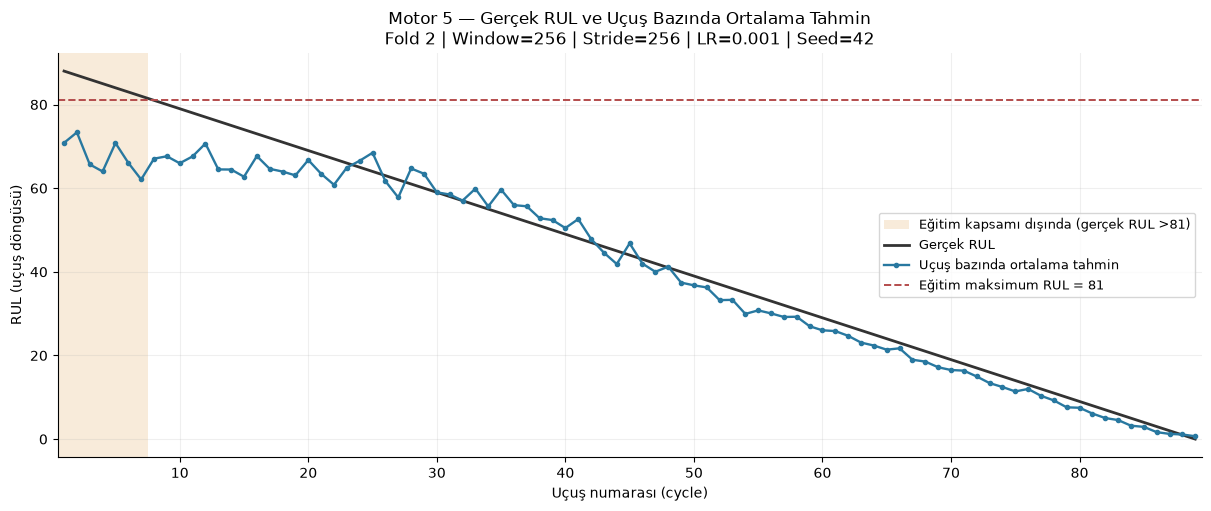

In [7]:
# Önceki hücrede doğrulanan tahminleri yeniden kullan.
assert (
    motor5_predictions.groupby("cycle")["actual_rul"]
    .nunique().eq(1).all()
)

motor5_flight_predictions = (
    motor5_predictions.groupby("cycle", as_index=False)
    .agg(
        actual_rul=("actual_rul", "first"),
        mean_predicted_rul=("predicted_rul", "mean"),
        window_count=("window_id", "size"),
    )
    .sort_values("cycle")
    .reset_index(drop=True)
)

motor5_flight_predictions["outside_training_range"] = (
    motor5_flight_predictions["actual_rul"].gt(motor5_train_max)
)

assert len(motor5_flight_predictions) == 89
assert motor5_flight_predictions["window_count"].sum() == 3990
assert motor5_flight_predictions["outside_training_range"].sum() == 7

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)

# Her kapsam dışı uçuşun çevresini ayrı ayrı gölgele.
# Ardışık uçuşlar grafikte tek bir bölge oluşturur.
outside_cycles = motor5_flight_predictions.loc[
    motor5_flight_predictions["outside_training_range"], "cycle"
]

for index, cycle in enumerate(outside_cycles):
    ax.axvspan(
        cycle - 0.5,
        cycle + 0.5,
        color="#D99435",
        alpha=0.18,
        linewidth=0,
        label="Eğitim kapsamı dışında (gerçek RUL >81)"
        if index == 0 else None,
    )

ax.plot(
    motor5_flight_predictions["cycle"],
    motor5_flight_predictions["actual_rul"],
    color="#333333",
    linewidth=2,
    label="Gerçek RUL",
)
ax.plot(
    motor5_flight_predictions["cycle"],
    motor5_flight_predictions["mean_predicted_rul"],
    color="#2878A0",
    linewidth=1.7,
    marker="o",
    markersize=3,
    label="Uçuş bazında ortalama tahmin",
)
ax.axhline(
    motor5_train_max,
    color="#B44C4C",
    linestyle="--",
    linewidth=1.4,
    label=f"Eğitim maksimum RUL = {motor5_train_max:.0f}",
)

ax.set(
    title=(
        "Motor 5 — Gerçek RUL ve Uçuş Bazında Ortalama Tahmin\n"
        "Fold 2 | Window=256 | Stride=256 | LR=0.001 | Seed=42"
    ),
    xlabel="Uçuş numarası (cycle)",
    ylabel="RUL (uçuş döngüsü)",
    xlim=(
        motor5_flight_predictions["cycle"].min() - 0.5,
        motor5_flight_predictions["cycle"].max() + 0.5,
    ),
)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=9)

plt.show()

## Motor 5 — Eğitim Kapsamı Dışındaki Pencerelerin Toplam Hataya Katkısı

Uçuş bazındaki grafik, yüksek RUL değerlerinde düşük tahmin eğiliminin
hem eğitim kapsamı dışında hem de kapsam içindeki erken uçuşlarda
bulunduğunu göstermektedir.

Bu adımda bütün validation pencereleri, eğitim RUL kapsamındaki
pencereler (RUL ≤81) ve kapsam dışındaki pencereler (RUL >81)
için MAE, RMSE ve Bias karşılaştırılacaktır.

Ayrıca kapsam dışındaki 277 pencerenin toplam karesel hataya
(SSE) katkısı hesaplanacaktır. Bu payın pencere payı olan %6,94
ile karşılaştırılması, hatanın bu grupta ne ölçüde yoğunlaştığını
gösterecektir. SSE payı, RMSE'nin doğrudan yüzdesi değildir.

Bu ayrım yalnızca tanısal amaçlıdır. Kapsam dışı kayıtlar resmî
validation değerlendirmesinden çıkarılmayacak ve gözlemlenen
farklar nedensel etki olarak yorumlanmayacaktır.

In [8]:
motor5_outside = motor5_predictions["actual_rul"].gt(motor5_train_max)

motor5_scope_groups = {
    "Tüm validation pencereleri": motor5_predictions,
    "Eğitim kapsamında (RUL ≤81)": motor5_predictions.loc[~motor5_outside],
    "Eğitim kapsamı dışında (RUL >81)": motor5_predictions.loc[motor5_outside],
}

motor5_total_sse = motor5_predictions["squared_error"].sum()
assert motor5_total_sse > 0

motor5_scope_rows = []

for group_name, frame in motor5_scope_groups.items():
    group_sse = frame["squared_error"].sum()

    motor5_scope_rows.append({
        "Grup": group_name,
        "Pencere sayısı": len(frame),
        "Benzersiz uçuş sayısı": frame["cycle"].nunique(),
        "Pencere payı (%)": 100 * len(frame) / len(motor5_predictions),
        "MAE": frame["absolute_error"].mean(),
        "RMSE": np.sqrt(frame["squared_error"].mean()),
        "Bias": frame["error"].mean(),
        "SSE": group_sse,
        "Toplam SSE payı (%)": 100 * group_sse / motor5_total_sse,
    })

motor5_scope_metrics = pd.DataFrame(motor5_scope_rows).set_index("Grup")

# İki alt grup bütün validation kümesini eksiksiz kapsamalı.
motor5_scope_parts = motor5_scope_metrics.iloc[1:]
assert motor5_scope_parts["Pencere sayısı"].sum() == 3990
assert motor5_scope_parts["Benzersiz uçuş sayısı"].sum() == 89
assert np.isclose(motor5_scope_parts["SSE"].sum(), motor5_total_sse)
assert motor5_outside.sum() == 277

display(motor5_scope_metrics.style.format({
    "Pencere sayısı": "{:d}",
    "Benzersiz uçuş sayısı": "{:d}",
    "Pencere payı (%)": "{:.2f}",
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "Bias": "{:+.4f}",
    "SSE": "{:.2f}",
    "Toplam SSE payı (%)": "{:.2f}",
}))

outside_window_share = 100 * motor5_outside.mean()
outside_sse_share = (
    100
    * motor5_predictions.loc[motor5_outside, "squared_error"].sum()
    / motor5_total_sse
)

print(
    f"Kapsam dışı pencereler: toplam pencerelerin %{outside_window_share:.2f}'si, "
    f"toplam SSE'nin %{outside_sse_share:.2f}'si."
)
print("Resmî validation kapsamı korundu: 3990 pencerenin tamamı değerlendirildi.")

,Pencere sayısı,Benzersiz uçuş sayısı,Pencere payı (%),MAE,RMSE,Bias,SSE,Toplam SSE payı (%)
Grup,,,,,,,,
Tüm validation pencereleri,3990,89,100.00,4.8644,7.0372,-3.2171,197591.22,100.00
Eğitim kapsamında (RUL ≤81),3713,82,93.06,3.9722,5.5014,-2.2019,112377.21,56.87
Eğitim kapsamı dışında (RUL >81),277,7,6.94,16.8247,17.5394,-16.8247,85214.01,43.13


Kapsam dışı pencereler: toplam pencerelerin %6.94'si, toplam SSE'nin %43.13'si.
Resmî validation kapsamı korundu: 3990 pencerenin tamamı değerlendirildi.


## Motor 5 — Sonuç ve Değerlendirme

### Eğitim kapsamı dışında hata yoğunlaşıyor

Fold 2’de eğitim maksimum RUL değeri 81’dir. Motor 5’in bu sınırı
aşan 277 validation penceresi, 7 uçuşa karşılık gelmektedir.

Bu pencereler toplamın yalnızca **%6,94’ünü**, toplam karesel hatanın
(SSE) ise **%43,13’ünü** oluşturmaktadır. Dolayısıyla kapsam dışındaki
örnekler, Motor 5’in toplam hatasına pencere paylarının oldukça
üzerinde katkı yapmaktadır.

| Değerlendirme grubu | MAE | RMSE | Bias |
|:--|--:|--:|--:|
| Tüm validation pencereleri | 4,8644 | 7,0372 | −3,2171 |
| Eğitim kapsamında: RUL ≤81 | 3,9722 | 5,5014 | −2,2019 |
| Eğitim kapsamı dışında: RUL >81 | 16,8247 | 17,5394 | −16,8247 |

### Sorun yalnızca eğitim kapsamının aşılmasıyla sınırlı değil

Eğitim üst sınırına yakın **75–81** aralığında MAE **10,8117** ve
Bias **−10,8044** bulunmuştur. Kapsam dışındaki **82–88** aralığında
bu değerler sırasıyla **16,8247** ve **−16,8247** olmuştur.

Bu sonuçlar, düşük tahmin eğiliminin eğitim kapsamı içerisinde de
belirgin olduğunu ve kapsam dışındaki grupta daha büyük hatalarla
birlikte görüldüğünü göstermektedir. Eğitim sınırında ani bir hata
sıçraması olduğu veya farkın yalnızca sınır aşımından kaynaklandığı
bu karşılaştırmayla kanıtlanamaz.

Uçuş bazındaki grafikte, erken uçuşların ortalama tahminleri yaklaşık
60–73 RUL çevresinde toplanmaktadır. Bu davranış kapsam dışındaki
ilk uçuşlardan sonra da sürmektedir. Görünüm, yüksek RUL değerlerini
ayırt etmede güçlük yaşandığını düşündürür; modelde kesin bir tahmin
üst sınırı bulunduğunu göstermez.

### Bulguların yorumu ve çözüm öncelikleri

Eğitim RUL kapsamının aşılması, yüksek hataların yoğunlaştığı önemli
bir koşuldur. Ancak gözlenen ilişki nedensellik kanıtı değildir.
Yüksek RUL değerlerinin eğitimde seyrek temsili, motorlar arasındaki
farklar ve erken yaşam dönemindeki sensör bilgilerinin RUL’u ayırt
etme gücü birlikte etkili olabilir.

Gelecekte yapılacak geliştirmelerde şu öncelikler değerlendirilebilir:

1. **Yüksek RUL temsilini güçlendirmek:** Mümkünse bağımsız eğitim
   motorlarından yüksek RUL örnekleri sağlamak. Validation veya
   resmî test motorları bu amaçla eğitime aktarılmamalıdır.
2. **Mevcut eğitim verisindeki dengesizliği kontrollü olarak sınamak:**
   Eğitim aralıklarına göre ağırlıklandırma denenebilir. Ancak bu
   yaklaşım, eğitimde bulunmayan RUL 82–88 değerlerini veya yeni motor
   çeşitliliğini üretmez; kapsam dışına genellemeyi garanti etmez.
3. **Başarıyı yalnızca genel hata ile değerlendirmemek:** Olası
   iyileştirmelerde yüksek RUL hatalarıyla birlikte düşük RUL
   performansı ve Bias da izlenmelidir. Bütün tahminlere sabit bir
   düzeltme eklemek, RUL’a göre değişen hatayı çözmeyebilir.

### Kapsam ve sınırlılıklar

Bu çalışma tek bir Motor 5 validation koşusuna dayalı tanısal analizdir.
Aynı uçuşun pencereleri bağımsız gözlemler değildir; kapsam dışındaki
277 pencere yalnızca 7 uçuşu temsil etmektedir.

Resmî validation değerlendirmesi **3990 pencerenin tamamını** kapsamaya
devam etmektedir: **MAE=4,8644, RMSE=7,0372**. Alt grup sonuçları,
kapsam dışındaki örnekleri değerlendirmeden çıkarmak için kullanılmamıştır.

Bu aşamada yeniden eğitim veya veri ayrımlarında değişiklik yapılmadan
Motor 5’e yönelik hedefli teşhis analizi tamamlanmıştır.